# Encoder architectures under one training protocol
**Protocol** (`encoder_protocol_config`): every encoder is trained for exactly 200 epochs on the same triplets for a given seed (edge-distance triplets of instance-1 elites, `edge`), with the same run split, margin and optimizer; the checkpoint is the model after the last epoch, the validation loss is only logged. Seeds shift the initialization and the training triplets.

**Architectures** (sizes of the LSTM):
- `lstm`: the LSTM of the original pipeline (`RNNEncoder`), canonical orientation; the base;
- `incidence_mlp`: MLP on the edge incidence vector of the full cycle (190 binary features);
- `edge_deepsets`: DeepSets over the 20 undirected edges, `phi([e_a + e_b, e_a * e_b])`, mean pooling, `rho`.

The last two are invariant to the direction and the rotation of the cycle by construction (`tests/test_encoder_invariance.py`).

**Selection rule** (fixed before the results of all seeds were seen; `A.select_architecture`): the criterion of one trained encoder is the mean difference to the untrained LSTM of ARI and `end_equal` at k = 20 and 50 on the **validation runs of instance 1**; an architecture scores the mean over its 3 seeds. The test runs and instance 2 are only reported and never used for the choice. The highest mean wins unless another architecture is tied with it (difference of the means smaller than the larger of the two standard deviations over seeds); among tied architectures the simplest and cheapest wins: `incidence_mlp`, then `edge_deepsets`, then `lstm`. The data variants are reported for the selected architecture and for any other architecture whose variants were trained (an earlier, provisional choice on seed 0 alone picked `edge_deepsets`, whose data variants were therefore trained first).

**Local term** (`local_term_config`): the triplet loss of (elite, the elite after one swap or 2-opt move, one of its nearest elites; exact edge distances) added to the edge triplets with a weight w. Rule for w (fixed before its results were seen): on `incidence_mlp`, seed 0 of every w > 0 in {0.25, 0.5, 1}; w* = the highest criterion on the validation runs of instance 1 (a tie goes to the smaller w); w* gets 3 seeds and is compared with w = 0 (the edge objective alone, 3 seeds) by the same rule, a tie going to w = 0 (simpler).

**Evaluation sets**: validation runs of instance 1 (20 runs), test runs of instance 1 (100 new GA runs, seeds never used before, no training or selection on them), instance 2 (TSP seed 99, all 100 runs, no retraining).

**Limitation: no transfer between instances.** No encoder trained on instance 1 transfers to instance 2; the invariant ones are there even worse than their own random init (they learn which city pairs and cities matter, and that is specific to the instance). Training on the instance itself gives the quality of instance 1 (last section), so training per instance is the standard; an encoder with instance features (e.g. edge lengths) is left for later. The LSTM is closed and not fully converged at 200 epochs (its validation loss still falls by about 1% per 20 epochs).

**Reporting**: every trained encoder as `mean±sd over seeds (gain over its own random init) [difference to the untrained LSTM]`, untrained encoders as `mean±sd` over the same seeds; the emphasis on k >= 20; next to ARI the soft agreement (per tour the Spearman correlation between its distances to the k centers in the permutation space and in the embedding, averaged over tours, k = 20 and 50); `end_equal` with its chance level sum p_perm * p_emb in a separate table; recall@k only as a local diagnostic.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == 'notebooks':
    os.chdir("..")

In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np
import torch
from dl_permutations import encoder_architectures as A
from dl_permutations import encoder_variants as V
from dl_permutations import stn_clusters as S

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sets = A.evaluation_sets()
for name, d in sets.items():
    print(f"{name}: {len(d['perm'])} elites, {len(np.unique(d['run_id']))} runs, "
          f"best tour length {d['fitness'].min():.3f}")

instance 1, validation runs: 392 elites, 20 runs, best tour length 41.979
instance 1, test runs: 1850 elites, 100 runs, best tour length 41.049
instance 2, all runs: 2001 elites, 100 runs, best tour length 38.457
instance 2, validation runs: 376 elites, 20 runs, best tour length 40.718


## Models and loss curves
Mean training / validation loss over the first, the second-to-last and the last 20 epochs and the relative change between the last two windows; a change near 0 means the loss has flattened.

         encoder epochs train first 20 train prev 20 train last 20 train change val first 20 val prev 20 val last 20 val change val acc last
         lstm s0    200          0.138         0.092         0.092       -0.003        0.164       0.112       0.111     -0.012        0.868
         lstm s1    200          0.136         0.092         0.092       -0.004        0.159       0.112       0.110     -0.012        0.868
         lstm s2    200          0.139         0.092         0.092       -0.002        0.164       0.114       0.112     -0.014        0.869
incidence_mlp s0    200          0.094         0.086         0.086       -0.001        0.102       0.097       0.097     -0.002        0.901
incidence_mlp s1    200          0.094         0.086         0.086       -0.000        0.102       0.098       0.098      0.000        0.898
incidence_mlp s2    200          0.094         0.086         0.086        0.005        0.103       0.098       0.097     -0.002        0.898
edge_deepsets

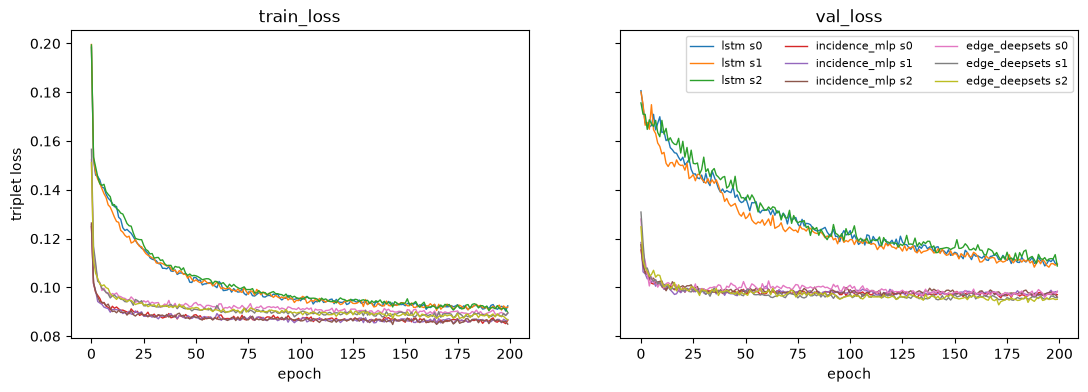

In [3]:
random_inits = {f"random init {arch} s{seed}": A.random_init(arch, device, seed)
                for arch in A.ARCHITECTURES for seed in A.PROTOCOL_SEEDS}
models = {**random_inits, **{f"{arch} s{seed}": A.load_or_fit(arch, device, seed=seed)
                             for arch in A.ARCHITECTURES for seed in A.PROTOCOL_SEEDS}}
histories = {name: A.load_history(name.split(" s")[0], seed=int(name.split(" s")[1]))
             for name in models if A.is_trained(name)}
rows = [{"encoder": name, **A.flat_check(h)} for name, h in histories.items()]
print(S.format_table(rows, list(rows[0])), end="\n\n")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, key in zip(axes, ("train_loss", "val_loss")):
    for name, h in histories.items():
        ax.plot([e[key] for e in h], label=name, lw=1)
    ax.set_title(key)
    ax.set_xlabel("epoch")
axes[0].set_ylabel("triplet loss")
axes[1].legend(fontsize=8, ncol=3)
plt.show()

## Selection of the architecture (validation runs of instance 1, 3 seeds)

In [4]:
comparison = {"instance 1, validation runs": A.evaluate(models, sets["instance 1, validation runs"], device)}
_, selection_tables, _ = comparison["instance 1, validation runs"]
scores = {arch: [A.selection_score(selection_tables, f"{arch} s{seed}") for seed in A.PROTOCOL_SEEDS]
          for arch in A.ARCHITECTURES}
best, selection = A.select_architecture(scores)
for row in selection:
    print(f"{row['architecture']:14s} criterion per seed {np.round(scores[row['architecture']], 3)} "
          f"mean {row['mean']:+.3f} sd {row['sd']:.3f} tied with the top: {row['tied with top']}")
print("selected:", best)

lstm           criterion per seed [0.175 0.157 0.159] mean +0.164 sd 0.010 tied with the top: True
incidence_mlp  criterion per seed [0.17  0.195 0.18 ] mean +0.182 sd 0.013 tied with the top: True
edge_deepsets  criterion per seed [0.176 0.165 0.215] mean +0.185 sd 0.026 tied with the top: True
selected: incidence_mlp


## Diagnostic: neighbours after one swap vs one 2-opt move
For every distinct cycle of a set, 3 neighbours after exactly one random swap and 3 after one random 2-opt move (the same neighbours for every encoder). recall@k: share of neighbours among the k nearest cycles of the anchor in the embedding (the other cycles of the set as competitors); `edge recall@1`: the same in edge distance; `d_emb / median`: embedding distance to the neighbour relative to the median pair distance. A 2-opt move changes 2 edges, a swap up to 4, so in edge distance the 2-opt neighbour is always the closer one.

In [5]:
diagnostic = {name: models[name] for name in ("random init lstm s0", "lstm s0", "random init incidence_mlp s0",
                                              "incidence_mlp s0", "random init edge_deepsets s0", "edge_deepsets s0")}
for set_name in ("instance 1, validation runs", "instance 1, test runs", "instance 2, all runs"):
    ranks = {name: V.move_neighbour_ranks(lambda P, m=m: A.embed(m, P, device), sets[set_name]["perm"])
             for name, m in diagnostic.items()}
    print(f"===== {set_name}")
    for title, table in V.move_recall_tables(ranks).items():
        print(title)
        print(S.format_table(table, list(table[0])), end="\n\n")

===== instance 1, validation runs
single-move neighbours: recall@k
                     encoder  move    n d_edge recall@1 recall@5 recall@10 edge recall@1 d_emb / median
         random init lstm s0  swap 1176  3.568    0.452    0.688     0.743         0.683          0.082
         random init lstm s0 2-opt 1160  2.000    0.414    0.641     0.699         1.000          0.104
                     lstm s0  swap 1176  3.568    0.402    0.695     0.797         0.683          0.399
                     lstm s0 2-opt 1160  2.000    0.525    0.866     0.920         1.000          0.315
random init incidence_mlp s0  swap 1176  3.568    0.518    0.882     0.946         0.683          0.565
random init incidence_mlp s0 2-opt 1160  2.000    0.797    0.997     1.000         1.000          0.429
            incidence_mlp s0  swap 1176  3.568    0.451    0.786     0.879         0.683          0.402
            incidence_mlp s0 2-opt 1160  2.000    0.700    0.961     0.988         1.000          0.2

===== instance 1, test runs
single-move neighbours: recall@k
                     encoder  move    n d_edge recall@1 recall@5 recall@10 edge recall@1 d_emb / median
         random init lstm s0  swap 5550  3.580    0.375    0.601     0.660         0.612          0.071
         random init lstm s0 2-opt 5523  2.000    0.365    0.588     0.645         1.000          0.081
                     lstm s0  swap 5550  3.580    0.275    0.495     0.595         0.612          0.413
                     lstm s0 2-opt 5523  2.000    0.433    0.715     0.801         1.000          0.311
random init incidence_mlp s0  swap 5550  3.580    0.412    0.737     0.817         0.612          0.564
random init incidence_mlp s0 2-opt 5523  2.000    0.745    0.983     0.995         1.000          0.435
            incidence_mlp s0  swap 5550  3.580    0.327    0.606     0.702         0.612          0.411
            incidence_mlp s0 2-opt 5523  2.000    0.602    0.883     0.934         1.000          0.277
ran

===== instance 2, all runs
single-move neighbours: recall@k
                     encoder  move    n d_edge recall@1 recall@5 recall@10 edge recall@1 d_emb / median
         random init lstm s0  swap 5991  3.598    0.368    0.597     0.654         0.581          0.063
         random init lstm s0 2-opt 5960  2.000    0.356    0.581     0.633         1.000          0.074
                     lstm s0  swap 5991  3.598    0.286    0.489     0.560         0.581          0.432
                     lstm s0 2-opt 5960  2.000    0.310    0.543     0.619         1.000          0.400
random init incidence_mlp s0  swap 5991  3.598    0.373    0.708     0.797         0.581          0.570
random init incidence_mlp s0 2-opt 5960  2.000    0.733    0.980     0.994         1.000          0.438
            incidence_mlp s0  swap 5991  3.598    0.281    0.489     0.570         0.581          0.451
            incidence_mlp s0 2-opt 5960  2.000    0.502    0.711     0.779         1.000          0.283
rand

## Architecture comparison
Per evaluation set: the metrics averaged over k = 20 and 50, the geometry and probes, then ARI, the soft agreement, `best_strength`, `n_end` and `end_equal` per k, every trained row as `mean±sd (gain over own random init) [difference to the untrained LSTM]`; the permutation space and the tie-breaking ceiling are absolute rows; last the chance level of `end_equal`. Instance 2 shows the transfer without retraining.

In [6]:
for set_name in ("instance 1, validation runs", "instance 1, test runs", "instance 2, all runs"):
    d = sets[set_name]
    if set_name not in comparison:
        comparison[set_name] = A.evaluate(models, d, device)
    geometry, tables, results = comparison[set_name]
    print(f"===== {set_name}")
    for title, table in A.gain_report(geometry, tables, results, d).items():
        print(title)
        print(S.format_table(table, list(table[0])), end="\n\n")

===== instance 1, validation runs
mean over k = 20, 50
                            encoder                     ari k>=20                    soft k>=20               end_equal k>=20           best_strength k>=20
         random init lstm (3 seeds)                   0.083±0.009                   0.077±0.032                   0.375±0.000                   0.308±0.014
random init incidence_mlp (3 seeds)                   0.090±0.009                   0.457±0.045                   0.433±0.058                   0.458±0.029
random init edge_deepsets (3 seeds)                   0.115±0.006                   0.383±0.050                   0.425±0.075                   0.433±0.101
                     lstm (3 seeds) 0.162±0.006 (+0.079) [+0.069] 0.723±0.006 (+0.646) [+0.616] 0.633±0.014 (+0.258) [+0.258] 0.342±0.038 (+0.033) [+0.017]
            incidence_mlp (3 seeds) 0.215±0.016 (+0.125) [+0.122] 0.767±0.003 (+0.311) [+0.660] 0.617±0.014 (+0.183) [+0.242] 0.342±0.029 (-0.117) [+0.017]
         

===== instance 1, test runs
mean over k = 20, 50
                            encoder                     ari k>=20                    soft k>=20               end_equal k>=20           best_strength k>=20
         random init lstm (3 seeds)                   0.031±0.006                   0.047±0.056                   0.192±0.010                   0.310±0.040
random init incidence_mlp (3 seeds)                   0.053±0.008                   0.424±0.014                   0.293±0.059                   0.683±0.098
random init edge_deepsets (3 seeds)                   0.050±0.005                   0.433±0.055                   0.292±0.065                   0.500±0.036
                     lstm (3 seeds) 0.093±0.002 (+0.062) [+0.055] 0.685±0.004 (+0.639) [+0.680] 0.397±0.020 (+0.205) [+0.197] 0.603±0.055 (+0.293) [+0.278]
            incidence_mlp (3 seeds) 0.121±0.008 (+0.069) [+0.083] 0.740±0.000 (+0.316) [+0.734] 0.447±0.038 (+0.153) [+0.247] 0.613±0.039 (-0.070) [+0.288]
            edg

===== instance 2, all runs
mean over k = 20, 50
                            encoder                     ari k>=20                    soft k>=20               end_equal k>=20           best_strength k>=20
         random init lstm (3 seeds)                   0.024±0.001                   0.051±0.017                   0.140±0.010                   0.345±0.126
random init incidence_mlp (3 seeds)                   0.048±0.010                   0.407±0.046                   0.293±0.067                   0.470±0.268
random init edge_deepsets (3 seeds)                   0.057±0.009                   0.419±0.019                   0.325±0.065                   0.628±0.090
                     lstm (3 seeds) 0.030±0.006 (+0.006) [+0.007] 0.216±0.039 (+0.165) [+0.170] 0.217±0.028 (+0.077) [+0.077] 0.362±0.033 (+0.017) [-0.128]
            incidence_mlp (3 seeds) 0.030±0.002 (-0.018) [+0.008] 0.251±0.018 (-0.156) [+0.204] 0.230±0.013 (-0.063) [+0.090] 0.405±0.030 (-0.065) [-0.085]
            edge

## Local term: weight scan on incidence_mlp (seed 0)
Trade-off between local and global geometry: recall@5 of the single-move neighbours (swap, 2-opt) against ARI and the soft agreement at k >= 20 and the Spearman correlation of all pair distances, on the validation and the test runs; `criterion` is the selection criterion (validation only).

===== instance 1, validation runs
                     encoder recall@5 swap recall@5 2-opt ARI k>=20 soft k>=20 spearman criterion
         random init lstm s0         0.688          0.641     0.093      0.108    0.159       nan
random init incidence_mlp s0         0.882          0.997     0.100      0.412    0.416       nan
        incidence_mlp w=0 s0         0.786          0.961     0.208      0.768    0.826     0.170
     incidence_mlp w=0.25 s0         0.902          0.979     0.216      0.751    0.785     0.211
      incidence_mlp w=0.5 s0         0.906          0.984     0.231      0.749    0.786     0.206
        incidence_mlp w=1 s0         0.930          0.989     0.229      0.737    0.779     0.218



===== instance 1, test runs
                     encoder recall@5 swap recall@5 2-opt ARI k>=20 soft k>=20 spearman criterion
         random init lstm s0         0.601          0.588     0.038      0.005    0.157       nan
random init incidence_mlp s0         0.737          0.983     0.061      0.431    0.411       nan
        incidence_mlp w=0 s0         0.606          0.883     0.129      0.740    0.845     0.191
     incidence_mlp w=0.25 s0         0.791          0.948     0.117      0.713    0.796     0.152
      incidence_mlp w=0.5 s0         0.831          0.963     0.133      0.720    0.800     0.178
        incidence_mlp w=1 s0         0.843          0.969     0.113      0.702    0.787     0.100



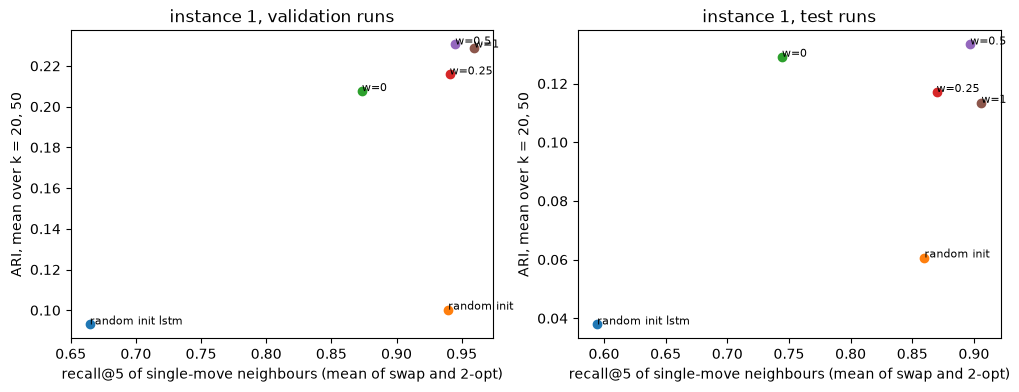

In [7]:
scan = {A.REFERENCE: models[A.REFERENCE], "random init incidence_mlp s0": models["random init incidence_mlp s0"]}
for w in A.LOCAL_WEIGHTS:
    scan[f"incidence_mlp w={w:g} s0"] = A.load_or_fit("incidence_mlp", device, local_weight=w) if w else models["incidence_mlp s0"]
scan_tables, tradeoff = {}, {}
for set_name in ("instance 1, validation runs", "instance 1, test runs"):
    d = sets[set_name]
    geometry, tables, _ = A.evaluate(scan, d, device)
    scan_tables[set_name] = tables
    k20 = {r["encoder"]: r for r in A.k20_table(tables)}
    geo = {r["encoder"]: r for r in geometry}
    rows = []
    for name, m in scan.items():
        ranks = V.move_neighbour_ranks(lambda P, m=m: A.embed(m, P, device), d["perm"])
        rows.append({"encoder": name, "recall@5 swap": float((ranks["swap"]["emb_rank"] < 5).mean()),
                     "recall@5 2-opt": float((ranks["2-opt"]["emb_rank"] < 5).mean()),
                     "ARI k>=20": k20[name]["ari k>=20"], "soft k>=20": k20[name]["soft k>=20"],
                     "spearman": geo[name]["spearman"],
                     "criterion": A.selection_score(tables, name) if A.is_trained(name) else float("nan")})
    tradeoff[set_name] = rows
    print(f"===== {set_name}")
    print(S.format_table(rows, list(rows[0])), end="\n\n")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (set_name, rows) in zip(axes, tradeoff.items()):
    for r in rows:
        x = (r["recall@5 swap"] + r["recall@5 2-opt"]) / 2
        ax.scatter(x, r["ARI k>=20"])
        ax.annotate(r["encoder"].replace("incidence_mlp ", "").replace(" s0", ""), (x, r["ARI k>=20"]), fontsize=8)
    ax.set_title(set_name)
    ax.set_xlabel("recall@5 of single-move neighbours (mean of swap and 2-opt)")
    ax.set_ylabel("ARI, mean over k = 20, 50")
plt.show()

## Local term: selection of the weight
w* = the best w > 0 on the validation runs with seed 0 (a tie goes to the smaller w); then w* with 3 seeds against w = 0 with 3 seeds by the selection rule (a tie goes to w = 0).

**Outcome and why it is not the default.** The rule selected w = 1 on the validation runs (criterion 0.214 ± 0.004 over 3 seeds against 0.182 ± 0.013 for w = 0). The test runs did not confirm it: ARI at k >= 20 is unchanged (0.125 vs 0.121), the soft agreement and `end_equal` are lower (0.713 vs 0.740, 0.395 vs 0.447) and only the local recall is higher. Reasons: the validation set has only 20 runs (`end_equal` moves in steps of 0.05 with a standard error of about 0.1) and the tie rule used only the spread over seeds, which leaves out the variance from the choice of runs; the win of w = 1 came mostly from `end_equal` at k = 50. The default stays w = 0, the local term is an option for local accuracy. The final selection uses a separate dev set of 100 runs and a bootstrap over runs (`notebooks/project_summary.ipynb`).

In [8]:
nonzero = [w for w in A.LOCAL_WEIGHTS if w]
seed0 = {w: A.selection_score(scan_tables["instance 1, validation runs"], f"incidence_mlp w={w:g} s0") for w in nonzero}
w_best = max(nonzero, key=lambda w: (seed0[w], -w))
print("seed 0 criterion per weight:", {w: round(v, 3) for w, v in seed0.items()}, "-> w* =", w_best)
weights = {A.REFERENCE: models[A.REFERENCE],
           **{f"random init incidence_mlp s{seed}": models[f"random init incidence_mlp s{seed}"] for seed in A.PROTOCOL_SEEDS}}
for seed in A.PROTOCOL_SEEDS:
    weights[f"incidence_mlp w=0 s{seed}"] = models[f"incidence_mlp s{seed}"]
    weights[f"incidence_mlp w={w_best:g} s{seed}"] = A.load_or_fit("incidence_mlp", device, seed=seed, local_weight=w_best)
weight_results = {set_name: A.evaluate(weights, sets[set_name], device)
                  for set_name in ("instance 1, validation runs", "instance 1, test runs")}
labels = ["w=0", f"w={w_best:g}"]
_, val_tables, _ = weight_results["instance 1, validation runs"]
weight_scores = {label: [A.selection_score(val_tables, f"incidence_mlp {label} s{seed}") for seed in A.PROTOCOL_SEEDS]
                 for label in labels}
w_choice, selection = A.select_architecture(weight_scores, simplicity=labels)
for row in selection:
    print(f"{row['architecture']:8s} criterion per seed {np.round(weight_scores[row['architecture']], 3)} "
          f"mean {row['mean']:+.3f} sd {row['sd']:.3f} tied with the top: {row['tied with top']}")
print("selected:", w_choice)
histories = {f"w={w_best:g} s{seed}": A.load_history("incidence_mlp", seed=seed, local_weight=w_best)
             for seed in A.PROTOCOL_SEEDS}
histories.update({f"w={w:g} s0": A.load_history("incidence_mlp", local_weight=w) for w in nonzero if w != w_best})
rows = [{"encoder": name, **A.flat_check(h)} for name, h in histories.items()]
print(S.format_table(rows, list(rows[0])), end="\n\n")
for set_name, (geometry, tables, results) in weight_results.items():
    d = sets[set_name]
    print(f"===== {set_name}")
    ranks = {name: V.move_neighbour_ranks(lambda P, m=m: A.embed(m, P, device), d["perm"])
             for name, m in weights.items() if name.endswith("s0")}
    for title, table in V.move_recall_tables(ranks).items():
        print(title)
        print(S.format_table(table, list(table[0])), end="\n\n")
    for title, table in A.gain_report(geometry, tables, results, d).items():
        print(title)
        print(S.format_table(table, list(table[0])), end="\n\n")

seed 0 criterion per weight: {0.25: 0.211, 0.5: 0.206, 1.0: 0.218} -> w* = 1.0


w=0      criterion per seed [0.17  0.195 0.18 ] mean +0.182 sd 0.013 tied with the top: False
w=1      criterion per seed [0.218 0.215 0.211] mean +0.214 sd 0.004 tied with the top: True
selected: w=1
  encoder epochs train first 20 train prev 20 train last 20 train change val first 20 val prev 20 val last 20 val change val acc last
   w=1 s0    200          0.115         0.097         0.097       -0.002        0.113       0.115       0.115     -0.001        0.883
   w=1 s1    200          0.115         0.097         0.097       -0.002        0.113       0.114       0.114      0.001        0.881
   w=1 s2    200          0.115         0.096         0.097        0.001        0.114       0.115       0.116      0.005        0.879
w=0.25 s0    200          0.104         0.092         0.092       -0.002        0.105       0.108       0.108      0.005        0.884
 w=0.5 s0    200          0.108         0.094         0.094       -0.003        0.110       0.112       0.112     -0.000        0

single-move neighbours: recall@k
                     encoder  move    n d_edge recall@1 recall@5 recall@10 edge recall@1 d_emb / median
         random init lstm s0  swap 1176  3.568    0.452    0.688     0.743         0.683          0.082
         random init lstm s0 2-opt 1160  2.000    0.414    0.641     0.699         1.000          0.104
random init incidence_mlp s0  swap 1176  3.568    0.518    0.882     0.946         0.683          0.565
random init incidence_mlp s0 2-opt 1160  2.000    0.797    0.997     1.000         1.000          0.429
        incidence_mlp w=0 s0  swap 1176  3.568    0.451    0.786     0.879         0.683          0.402
        incidence_mlp w=0 s0 2-opt 1160  2.000    0.700    0.961     0.988         1.000          0.278
        incidence_mlp w=1 s0  swap 1176  3.568    0.626    0.930     0.969         0.683          0.382
        incidence_mlp w=1 s0 2-opt 1160  2.000    0.825    0.989     0.997         1.000          0.279

recall@5 by segment length (po

single-move neighbours: recall@k
                     encoder  move    n d_edge recall@1 recall@5 recall@10 edge recall@1 d_emb / median
         random init lstm s0  swap 5550  3.580    0.375    0.601     0.660         0.612          0.071
         random init lstm s0 2-opt 5523  2.000    0.365    0.588     0.645         1.000          0.081
random init incidence_mlp s0  swap 5550  3.580    0.412    0.737     0.817         0.612          0.564
random init incidence_mlp s0 2-opt 5523  2.000    0.745    0.983     0.995         1.000          0.435
        incidence_mlp w=0 s0  swap 5550  3.580    0.327    0.606     0.702         0.612          0.411
        incidence_mlp w=0 s0 2-opt 5523  2.000    0.602    0.883     0.934         1.000          0.277
        incidence_mlp w=1 s0  swap 5550  3.580    0.533    0.843     0.897         0.612          0.387
        incidence_mlp w=1 s0 2-opt 5523  2.000    0.775    0.969     0.983         1.000          0.284

recall@5 by segment length (po

## Data variants
- `population_edge`: the edge objective on every distinct tour of the GA populations of the training runs of instance 1 (466 501 tours over all runs) instead of the elites only; `incidence_mlp` with 3 seeds, also with the local term (weight w*, 3 seeds; the local term is built on the elites);
- `elite_synthetic`: anchors only from the training elites, positive and negative its synthetic neighbours (1-5 random 2-opt moves or swaps, exact edge distance); seed 0;
- the `edge_deepsets` variants (seed 0) from the provisional choice.

In [9]:
variants = {name: m for name, m in models.items() if name.startswith("random init")}
histories = {}
for seed in A.PROTOCOL_SEEDS:
    variants[f"incidence_mlp edge s{seed}"] = models[f"incidence_mlp s{seed}"]
    variants[f"incidence_mlp population_edge s{seed}"] = A.load_or_fit("incidence_mlp", device, objective="population_edge", seed=seed)
    variants[f"incidence_mlp population_edge+local s{seed}"] = A.load_or_fit(
        "incidence_mlp", device, objective="population_edge", seed=seed, local_weight=w_best)
    histories[f"population_edge s{seed}"] = A.load_history("incidence_mlp", "population_edge", seed=seed)
    histories[f"population_edge+local s{seed}"] = A.load_history("incidence_mlp", "population_edge", seed=seed,
                                                               local_weight=w_best)
variants["incidence_mlp elite_synthetic s0"] = A.load_or_fit("incidence_mlp", device, objective="elite_synthetic")
variants["edge_deepsets edge s0"] = models["edge_deepsets s0"]
for objective in ("elite_synthetic", "population_edge"):
    variants[f"edge_deepsets {objective} s0"] = A.load_or_fit("edge_deepsets", device, objective=objective)
rows = [{"encoder": name, **A.flat_check(h)} for name, h in histories.items()]
print(S.format_table(rows, list(rows[0])), end="\n\n")
for set_name in ("instance 1, validation runs", "instance 1, test runs"):
    d = sets[set_name]
    geometry, tables, results = A.evaluate(variants, d, device)
    print(f"===== {set_name}")
    for title, table in A.gain_report(geometry, tables, results, d).items():
        print(title)
        print(S.format_table(table, list(table[0])), end="\n\n")

                 encoder epochs train first 20 train prev 20 train last 20 train change val first 20 val prev 20 val last 20 val change val acc last
      population_edge s0    200          0.132         0.119         0.119       -0.000        0.128       0.119       0.119      0.001        0.866
population_edge+local s0    200          0.152         0.131         0.131       -0.001        0.133       0.120       0.120     -0.002        0.880
      population_edge s1    200          0.131         0.121         0.121       -0.000        0.128       0.121       0.120     -0.006        0.859
population_edge+local s1    200          0.152         0.131         0.131       -0.002        0.134       0.121       0.120     -0.005        0.880
      population_edge s2    200          0.131         0.120         0.120       -0.001        0.128       0.120       0.119     -0.005        0.863
population_edge+local s2    200          0.151         0.131         0.130       -0.004        0.135      

===== instance 1, validation runs
mean over k = 20, 50
                                      encoder                     ari k>=20                    soft k>=20               end_equal k>=20           best_strength k>=20
                   random init lstm (3 seeds)                   0.083±0.009                   0.077±0.032                   0.375±0.000                   0.308±0.014
          random init incidence_mlp (3 seeds)                   0.090±0.009                   0.457±0.045                   0.433±0.058                   0.458±0.029
          random init edge_deepsets (3 seeds)                   0.115±0.006                   0.383±0.050                   0.425±0.075                   0.433±0.101
                 incidence_mlp edge (3 seeds) 0.215±0.016 (+0.125) [+0.122] 0.767±0.003 (+0.311) [+0.660] 0.617±0.014 (+0.183) [+0.242] 0.342±0.029 (-0.117) [+0.017]
      incidence_mlp population_edge (3 seeds) 0.195±0.015 (+0.105) [+0.102] 0.791±0.006 (+0.334) [+0.683] 0.450±0.0

===== instance 1, test runs
mean over k = 20, 50
                                      encoder                     ari k>=20                    soft k>=20               end_equal k>=20           best_strength k>=20
                   random init lstm (3 seeds)                   0.031±0.006                   0.047±0.056                   0.192±0.010                   0.310±0.040
          random init incidence_mlp (3 seeds)                   0.053±0.008                   0.424±0.014                   0.293±0.059                   0.683±0.098
          random init edge_deepsets (3 seeds)                   0.050±0.005                   0.433±0.055                   0.292±0.065                   0.500±0.036
                 incidence_mlp edge (3 seeds) 0.121±0.008 (+0.069) [+0.083] 0.740±0.000 (+0.316) [+0.734] 0.447±0.038 (+0.153) [+0.247] 0.613±0.039 (-0.070) [+0.288]
      incidence_mlp population_edge (3 seeds) 0.131±0.012 (+0.078) [+0.093] 0.764±0.004 (+0.340) [+0.758] 0.432±0.031 (+0

## Training per instance: instance 2
Validation runs of instance 2: every architecture trained on instance 1 (3 seeds) next to `incidence_mlp` and `edge_deepsets` trained on the training runs of instance 2 (seed 0).

In [10]:
instance_2 = {**models, **{f"{arch} trained on instance 2 s0": A.load_or_fit(arch, device, instance="tsp99")
                            for arch in ("incidence_mlp", "edge_deepsets")}}
d = sets["instance 2, validation runs"]
geometry, tables, results = A.evaluate(instance_2, d, device)
for title, table in A.gain_report(geometry, tables, results, d).items():
    print(title)
    print(S.format_table(table, list(table[0])), end="\n\n")

mean over k = 20, 50
                                     encoder                     ari k>=20                    soft k>=20               end_equal k>=20           best_strength k>=20
                  random init lstm (3 seeds)                   0.076±0.007                   0.159±0.022                   0.300±0.025                   0.408±0.038
         random init incidence_mlp (3 seeds)                   0.100±0.018                   0.373±0.043                   0.258±0.052                   0.558±0.038
         random init edge_deepsets (3 seeds)                   0.118±0.030                   0.402±0.049                   0.283±0.052                   0.467±0.038
                              lstm (3 seeds) 0.068±0.002 (-0.008) [-0.012] 0.232±0.010 (+0.073) [+0.069] 0.258±0.052 (-0.042) [-0.042] 0.500±0.132 (+0.092) [+0.050]
                     incidence_mlp (3 seeds) 0.082±0.007 (-0.017) [+0.002] 0.304±0.025 (-0.069) [+0.142] 0.208±0.014 (-0.050) [-0.092] 0.525±0.189 (-0.033

## STNs on the test runs (k = 20)

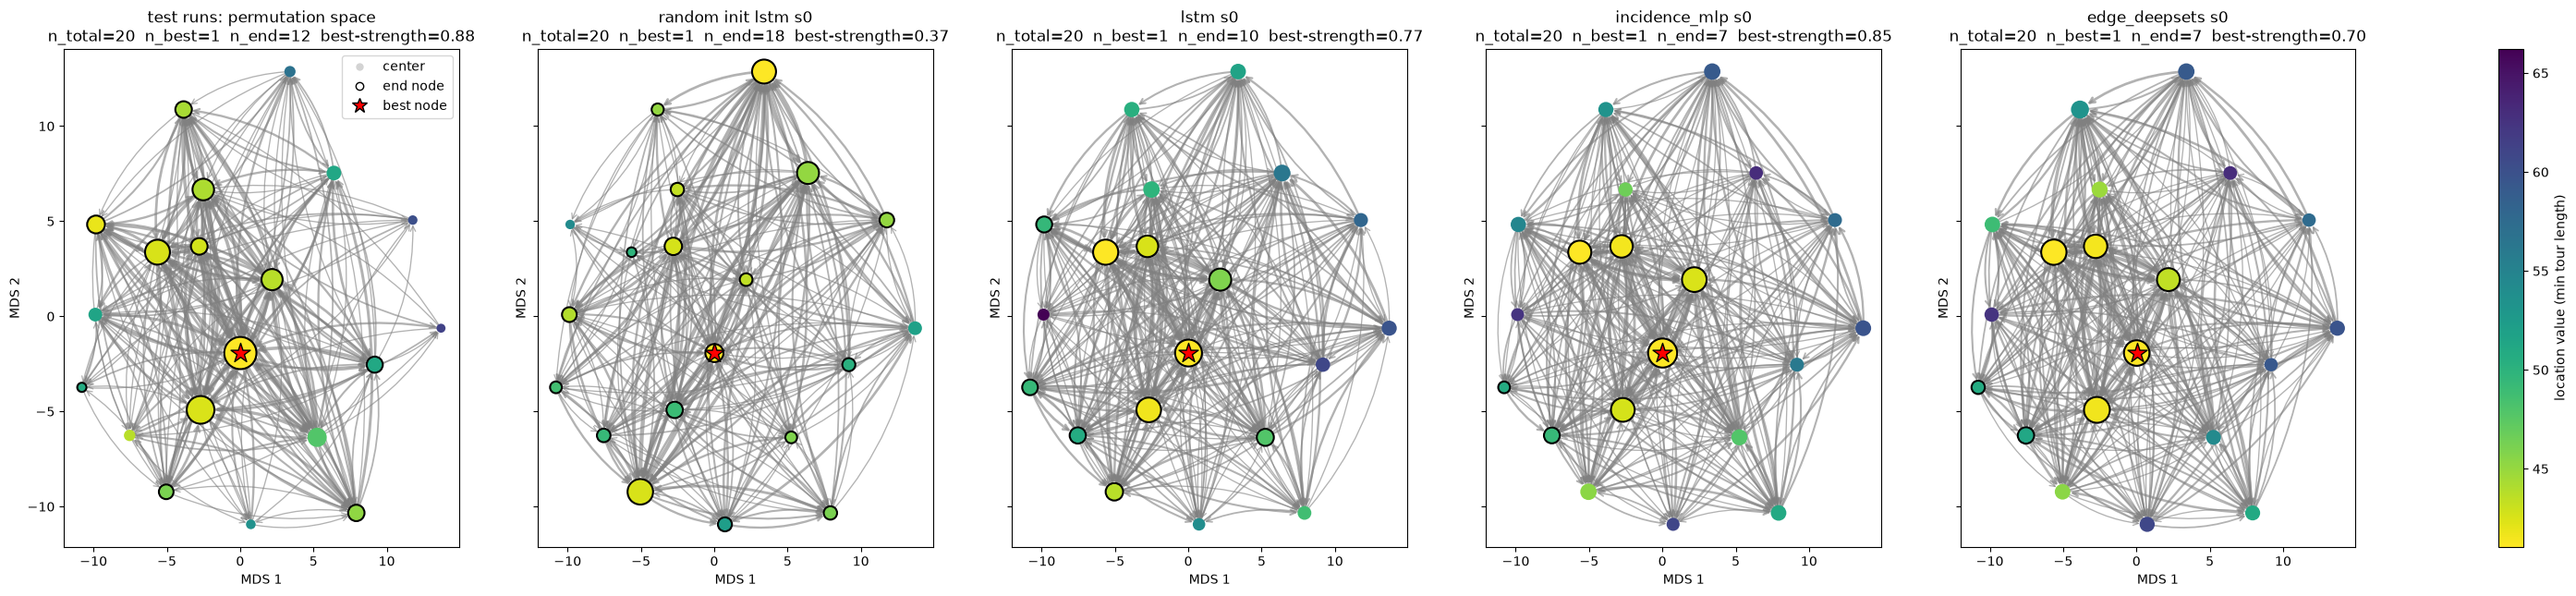

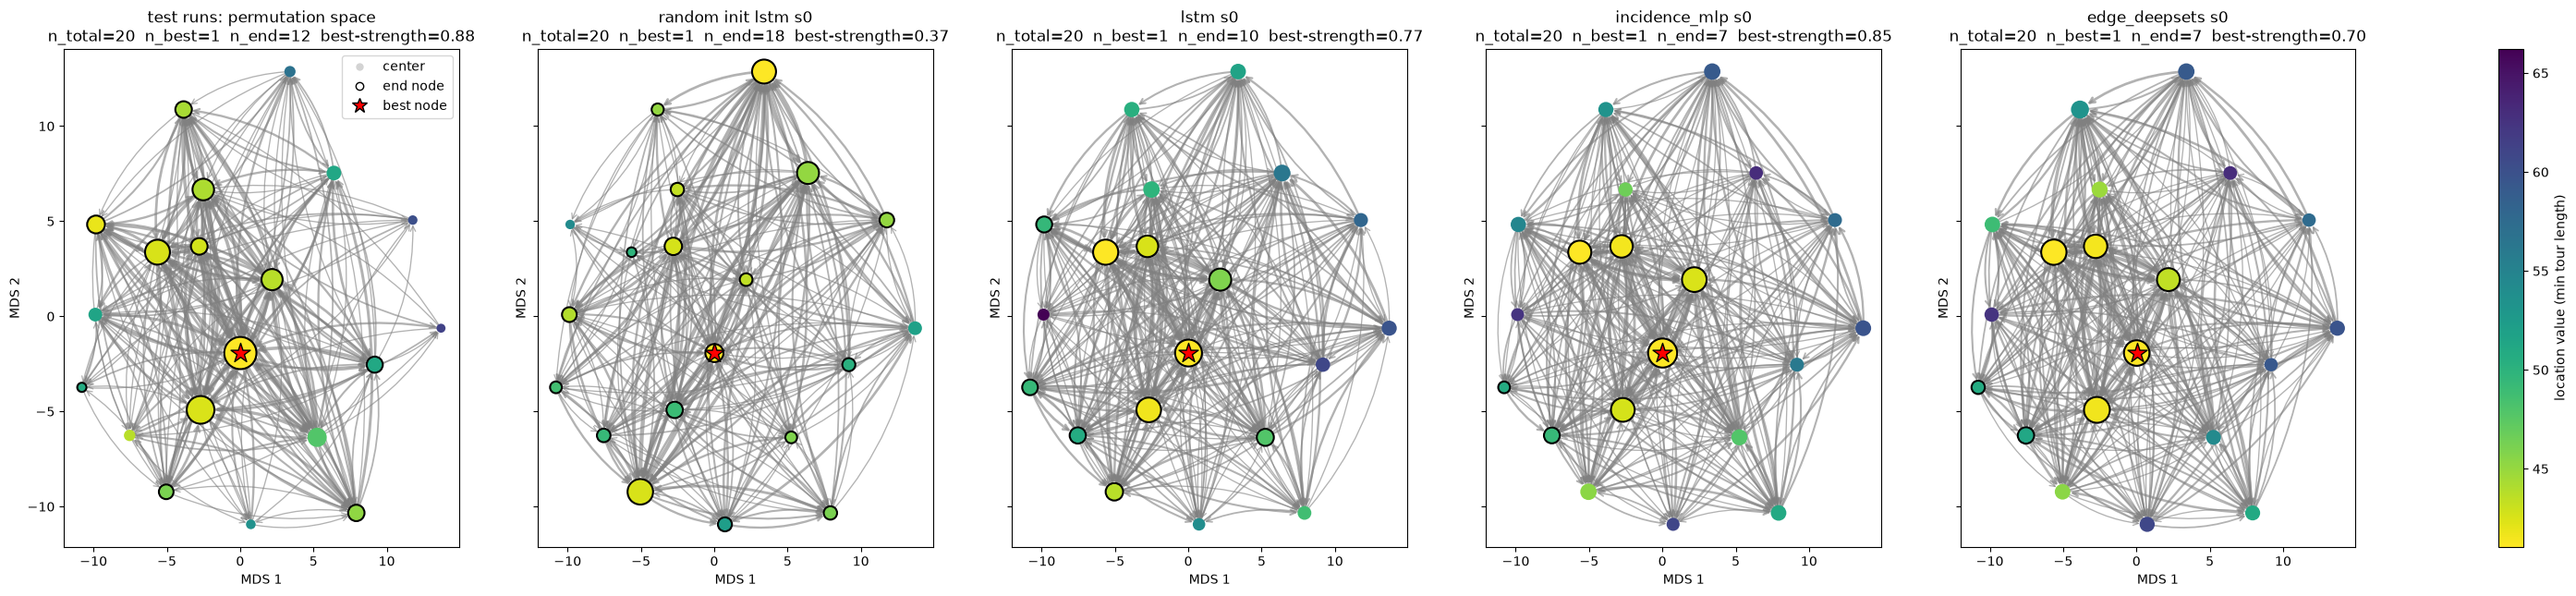

In [11]:
_, _, results = comparison["instance 1, test runs"]
res = results[A.REFERENCE, 20]
names = [A.REFERENCE, "lstm s0", "incidence_mlp s0", "edge_deepsets s0"]
S.plot_stns((res["G_perm"], *(results[name, 20]["G_emb"] for name in names)),
            ("test runs: permutation space", *names), res["pos"])